In [1]:
import pypsa
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import pvlib
import os
import warnings
warnings.filterwarnings('ignore')

try:
    pd.options.future.infer_string = False
except Exception:
    pass

font_path = os.path.expanduser('~/Library/Fonts/Cambria.ttc')
fm.fontManager.addfont(font_path)
plt.rcParams['font.family']      = 'Cambria'
plt.rcParams['mathtext.fontset'] = 'dejavuserif'
plt.rcParams['font.size']        = 11

base = os.path.join(os.path.expanduser("~"), "Documents", "EdenCampus_PhD")

# ── SHARED TIME STRUCTURE ──
def make_time_index(year):
    winter = pd.date_range(f'{year}-01-09', periods=168, freq='h')
    spring = pd.date_range(f'{year}-04-10', periods=168, freq='h')
    summer = pd.date_range(f'{year}-07-10', periods=168, freq='h')
    autumn = pd.date_range(f'{year}-10-09', periods=168, freq='h')
    return winter.append(spring).append(summer).append(autumn)

def get_pv_profile(year, time_index):
    print(f"  Downloading PVGIS {year}...")
    result = pvlib.iotools.get_pvgis_hourly(
        latitude=56.3398, longitude=-2.7967,
        start=year, end=year, map_variables=True)
    w = result[0]
    w.index = w.index.tz_localize(None)
    w.index = w.index.round('h')
    w = w[~w.index.duplicated(keep='first')]
    w['poa_total'] = (w['poa_direct'] +
                      w['poa_sky_diffuse'] +
                      w['poa_ground_diffuse'])
    pv_kw = 1000 * (w['poa_total'] / 1000) * (
        1 + (-0.004) * (w['temp_air'] - 25))
    pv_kw = pv_kw.clip(lower=0)
    profile = (pv_kw / 1000).clip(0, 1)
    return profile.reindex(time_index).fillna(0)

def make_demand(time_index):
    np.random.seed(42)
    def elec(ts):
        seasonal = {1:1.3,2:1.25,3:1.1,4:1.0,5:0.95,6:0.9,
                    7:0.9,8:0.9,9:1.0,10:1.1,11:1.2,12:1.3}
        hourly   = {0:0.1,1:0.1,2:0.1,3:0.1,4:0.1,5:0.15,
                    6:0.2,7:0.4,8:0.7,9:0.9,10:1.0,11:1.0,
                    12:0.85,13:0.9,14:1.0,15:0.95,16:0.85,17:0.7,
                    18:0.5,19:0.35,20:0.25,21:0.2,22:0.15,23:0.1}
        sf = seasonal[ts.month]
        wf = 0.3 if ts.weekday() >= 5 else 1.0
        hf = hourly[ts.hour]
        return (150 + 350 * hf) * sf * wf * np.random.uniform(0.95, 1.05)
    return pd.Series([elec(ts) for ts in time_index], index=time_index)

def run_s1_scenario(pv_profile, elec_demand, grid_price=280):
    n = pypsa.Network()
    n.set_snapshots(pv_profile.index)
    n.add("Carrier", "AC", co2_emissions=0.233)
    n.add("Bus", "Electricity Bus", carrier="AC")
    n.add("Generator", "Solar PV",
          bus="Electricity Bus", p_nom=1000,
          p_max_pu=pv_profile, marginal_cost=0)
    n.add("Generator", "Grid Import",
          bus="Electricity Bus", p_nom=2000,
          marginal_cost=grid_price)
    n.add("Generator", "Grid Export",
          bus="Electricity Bus", p_nom=500,
          p_max_pu=0, p_min_pu=-1, marginal_cost=-50)
    n.add("StorageUnit", "BESS",
          bus="Electricity Bus", p_nom=500, max_hours=4,
          efficiency_store=0.95, efficiency_dispatch=0.95,
          standing_loss=0.0002, cyclic_state_of_charge=True)
    n.add("Load", "Electrical Demand",
          bus="Electricity Bus", p_set=elec_demand)
    n.optimize(solver_name='highs')
    pv_gen      = n.generators_t.p["Solar PV"]
    grid_import = n.generators_t.p["Grid Import"]
    grid_export = n.generators_t.p["Grid Export"].abs()
    pv_consumed = pv_gen.sum() - grid_export.sum()
    return {
        'PV Generation (MWh)':  round(pv_gen.sum()    / 1000, 1),
        'Grid Import (MWh)':    round(grid_import.sum()/ 1000, 1),
        'Solar Fraction (%)':   round(pv_consumed / elec_demand.sum() * 100, 1),
        'CO2 Saved (tonnes)':   round(pv_consumed * 0.233 / 1000, 1),
        'Total Cost (£k)':      round(n.objective / 1000, 1),
        'Peak Import (kW)':     round(grid_import.max(), 1),
    }

# ── RUN WEATHER SENSITIVITY ──
print("WEATHER YEAR SENSITIVITY — S1: PV + BESS")
print("=" * 55)

weather_results = []
for year in [2020, 2021, 2022, 2023]:
    ti  = make_time_index(year)
    pv  = get_pv_profile(year, ti)
    dem = make_demand(ti)
    r   = run_s1_scenario(pv, dem)
    r['Year'] = str(year)
    weather_results.append(r)
    print(f"  {year}: PV={r['PV Generation (MWh)']} MWh | "
          f"Solar={r['Solar Fraction (%)']:.1f}% | "
          f"CO2={r['CO2 Saved (tonnes)']} t")

weather_df = pd.DataFrame(weather_results).set_index('Year')
print("\n" + weather_df.to_string())
print("\nWeather sensitivity complete!")

WEATHER YEAR SENSITIVITY — S1: PV + BESS


INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io: Writing time: 0.1s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 4032 primals, 9408 duals
Objective: 3.21e+07
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, StorageUnit-fix-p_dispatch-lower, StorageUnit-fix-p_dispatch-upper, StorageUnit-fix-p_store-lower, StorageUnit-fix-p_store-upper, StorageUnit-fix-state_of_charge-lower, StorageUnit-fix-state_of_charge-upper, StorageUnit-energy_balance were not assigned to the network.


Running HiGHS 1.13.1 (git hash: 1d267d9): Copyright (c) 2026 under MIT licence terms
LP linopy-problem-6vbp2z1l has 9408 rows; 4032 cols; 14112 nonzeros
Coefficient ranges:
  Matrix  [9e-01, 1e+00]
  Cost    [5e+01, 3e+02]
  Bound   [0e+00, 0e+00]
  RHS     [1e+00, 2e+03]
Presolving model
1304 rows, 3580 cols, 5516 nonzeros  0s
Dependent equations search running on 1304 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
1304 rows, 3580 cols, 5516 nonzeros  0s
Presolve reductions: rows 1304(-8104); columns 3580(-452); nonzeros 5516(-8596) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0     0.0000000000e+00 Ph1: 0(0) 0.0s
       1849     3.2071937307e+07 Pr: 0(0) 0.0s

Performed postsolve
Solving the original LP from the solution after postsolve

Model name          : linopy-problem-6vbp2z1l
Model status        : Optimal
Simplex   iterations: 1

INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io: Writing time: 0.02s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 4032 primals, 9408 duals
Objective: 2.80e+07
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, StorageUnit-fix-p_dispatch-lower, StorageUnit-fix-p_dispatch-upper, StorageUnit-fix-p_store-lower, StorageUnit-fix-p_store-upper, StorageUnit-fix-state_of_charge-lower, StorageUnit-fix-state_of_charge-upper, StorageUnit-energy_balance were not assigned to the network.


Running HiGHS 1.13.1 (git hash: 1d267d9): Copyright (c) 2026 under MIT licence terms
LP linopy-problem-3pye42bk has 9408 rows; 4032 cols; 14112 nonzeros
Coefficient ranges:
  Matrix  [9e-01, 1e+00]
  Cost    [5e+01, 3e+02]
  Bound   [0e+00, 0e+00]
  RHS     [1e+00, 2e+03]
Presolving model
1300 rows, 3570 cols, 5498 nonzeros  0s
Dependent equations search running on 1300 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
1300 rows, 3570 cols, 5498 nonzeros  0s
Presolve reductions: rows 1300(-8108); columns 3570(-462); nonzeros 5498(-8614) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0     0.0000000000e+00 Ph1: 0(0) 0.0s
       1809     2.7989688571e+07 Pr: 0(0) 0.0s

Performed postsolve
Solving the original LP from the solution after postsolve

Model name          : linopy-problem-3pye42bk
Model status        : Optimal
Simplex   iterations: 1

INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io: Writing time: 0.02s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 4032 primals, 9408 duals
Objective: 3.31e+07
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, StorageUnit-fix-p_dispatch-lower, StorageUnit-fix-p_dispatch-upper, StorageUnit-fix-p_store-lower, StorageUnit-fix-p_store-upper, StorageUnit-fix-state_of_charge-lower, StorageUnit-fix-state_of_charge-upper, StorageUnit-energy_balance were not assigned to the network.


Running HiGHS 1.13.1 (git hash: 1d267d9): Copyright (c) 2026 under MIT licence terms
LP linopy-problem-zer6y98a has 9408 rows; 4032 cols; 14112 nonzeros
Coefficient ranges:
  Matrix  [9e-01, 1e+00]
  Cost    [5e+01, 3e+02]
  Bound   [0e+00, 0e+00]
  RHS     [1e+00, 2e+03]
Presolving model
1303 rows, 3579 cols, 5513 nonzeros  0s
Dependent equations search running on 1303 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
1303 rows, 3579 cols, 5513 nonzeros  0s
Presolve reductions: rows 1303(-8105); columns 3579(-453); nonzeros 5513(-8599) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0     0.0000000000e+00 Ph1: 0(0) 0.0s
       1824     3.3081359015e+07 Pr: 0(0) 0.0s

Performed postsolve
Solving the original LP from the solution after postsolve

Model name          : linopy-problem-zer6y98a
Model status        : Optimal
Simplex   iterations: 1

INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io: Writing time: 0.02s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 4032 primals, 9408 duals
Objective: 3.02e+07
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, StorageUnit-fix-p_dispatch-lower, StorageUnit-fix-p_dispatch-upper, StorageUnit-fix-p_store-lower, StorageUnit-fix-p_store-upper, StorageUnit-fix-state_of_charge-lower, StorageUnit-fix-state_of_charge-upper, StorageUnit-energy_balance were not assigned to the network.


Running HiGHS 1.13.1 (git hash: 1d267d9): Copyright (c) 2026 under MIT licence terms
LP linopy-problem-843ntyso has 9408 rows; 4032 cols; 14112 nonzeros
Coefficient ranges:
  Matrix  [9e-01, 1e+00]
  Cost    [5e+01, 3e+02]
  Bound   [0e+00, 0e+00]
  RHS     [1e+00, 2e+03]
Presolving model
1302 rows, 3577 cols, 5509 nonzeros  0s
Dependent equations search running on 1302 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
1302 rows, 3577 cols, 5509 nonzeros  0s
Presolve reductions: rows 1302(-8106); columns 3577(-455); nonzeros 5509(-8603) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0     0.0000000000e+00 Ph1: 0(0) 0.0s
       1820     3.0217157992e+07 Pr: 0(0) 0.0s

Performed postsolve
Solving the original LP from the solution after postsolve

Model name          : linopy-problem-843ntyso
Model status        : Optimal
Simplex   iterations: 1

In [2]:
print("GRID PRICE SENSITIVITY — S1: PV + BESS")
print("=" * 55)

# Use 2023 as base year
ti_2023  = make_time_index(2023)
pv_2023  = get_pv_profile(2023, ti_2023)
dem_2023 = make_demand(ti_2023)

grid_prices   = [180, 220, 260, 280, 300, 340, 380]
price_results = []

for price in grid_prices:
    r = run_s1_scenario(pv_2023, dem_2023, grid_price=price)
    r['Grid Price (£/MWh)'] = price
    price_results.append(r)
    print(f"  £{price}/MWh: Solar={r['Solar Fraction (%)']:.1f}% | "
          f"Cost=£{r['Total Cost (£k)']:.0f}k | "
          f"Import={r['Grid Import (MWh)']} MWh")

price_df = pd.DataFrame(price_results).set_index('Grid Price (£/MWh)')
print("\n" + price_df.to_string())
print("\nGrid price sensitivity complete!")

GRID PRICE SENSITIVITY — S1: PV + BESS


INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io: Writing time: 0.11s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 4032 primals, 9408 duals
Objective: 1.94e+07
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, StorageUnit-fix-p_dispatch-lower, StorageUnit-fix-p_dispatch-upper, StorageUnit-fix-p_store-lower, StorageUnit-fix-p_store-upper, StorageUnit-fix-state_of_charge-lower, StorageUnit-fix-state_of_charge-upper, StorageUnit-energy_balance were not assigned to the network.


Running HiGHS 1.13.1 (git hash: 1d267d9): Copyright (c) 2026 under MIT licence terms
LP linopy-problem-q9huap6w has 9408 rows; 4032 cols; 14112 nonzeros
Coefficient ranges:
  Matrix  [9e-01, 1e+00]
  Cost    [5e+01, 2e+02]
  Bound   [0e+00, 0e+00]
  RHS     [1e+00, 2e+03]
Presolving model
1302 rows, 3577 cols, 5509 nonzeros  0s
Dependent equations search running on 1302 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
1302 rows, 3577 cols, 5509 nonzeros  0s
Presolve reductions: rows 1302(-8106); columns 3577(-455); nonzeros 5509(-8603) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0     0.0000000000e+00 Ph1: 0(0) 0.0s
       1820     1.9425315852e+07 Pr: 0(0) 0.0s

Performed postsolve
Solving the original LP from the solution after postsolve

Model name          : linopy-problem-q9huap6w
Model status        : Optimal
Simplex   iterations: 1

INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io: Writing time: 0.03s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 4032 primals, 9408 duals
Objective: 2.37e+07
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, StorageUnit-fix-p_dispatch-lower, StorageUnit-fix-p_dispatch-upper, StorageUnit-fix-p_store-lower, StorageUnit-fix-p_store-upper, StorageUnit-fix-state_of_charge-lower, StorageUnit-fix-state_of_charge-upper, StorageUnit-energy_balance were not assigned to the network.


Running HiGHS 1.13.1 (git hash: 1d267d9): Copyright (c) 2026 under MIT licence terms
LP linopy-problem-0uwfrt5i has 9408 rows; 4032 cols; 14112 nonzeros
Coefficient ranges:
  Matrix  [9e-01, 1e+00]
  Cost    [5e+01, 2e+02]
  Bound   [0e+00, 0e+00]
  RHS     [1e+00, 2e+03]
Presolving model
1302 rows, 3577 cols, 5509 nonzeros  0s
Dependent equations search running on 1302 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
1302 rows, 3577 cols, 5509 nonzeros  0s
Presolve reductions: rows 1302(-8106); columns 3577(-455); nonzeros 5509(-8603) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0     0.0000000000e+00 Ph1: 0(0) 0.0s
       1820     2.3742052708e+07 Pr: 0(0) 0.0s

Performed postsolve
Solving the original LP from the solution after postsolve

Model name          : linopy-problem-0uwfrt5i
Model status        : Optimal
Simplex   iterations: 1

...

Running HiGHS 1.13.1 (git hash: 1d267d9): Copyright (c) 2026 under MIT licence terms
LP linopy-problem-2k_w2do3 has 9408 rows; 4032 cols; 14112 nonzeros
Coefficient ranges:
  Matrix  [9e-01, 1e+00]
  Cost    [5e+01, 3e+02]
  Bound   [0e+00, 0e+00]
  RHS     [1e+00, 2e+03]
Presolving model
1302 rows, 3577 cols, 5509 nonzeros  0s
Dependent equations search running on 1302 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
1302 rows, 3577 cols, 5509 nonzeros  0s
Presolve reductions: rows 1302(-8106); columns 3577(-455); nonzeros 5509(-8603) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0     0.0000000000e+00 Ph1: 0(0) 0.0s
       1820     3.2375526421e+07 Pr: 0(0); Du: 0(3.53927e-14) 0.0s

Performed postsolve
Solving the original LP from the solution after postsolve

Model name          : linopy-problem-2k_w2do3
Model status        : Optimal
Sim

INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io: Writing time: 0.02s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 4032 primals, 9408 duals
Objective: 3.67e+07
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, StorageUnit-fix-p_dispatch-lower, StorageUnit-fix-p_dispatch-upper, StorageUnit-fix-p_store-lower, StorageUnit-fix-p_store-upper, StorageUnit-fix-state_of_charge-lower, StorageUnit-fix-state_of_charge-upper, StorageUnit-energy_balance were not assigned to the network.


Running HiGHS 1.13.1 (git hash: 1d267d9): Copyright (c) 2026 under MIT licence terms
LP linopy-problem-gb5riwax has 9408 rows; 4032 cols; 14112 nonzeros
Coefficient ranges:
  Matrix  [9e-01, 1e+00]
  Cost    [5e+01, 3e+02]
  Bound   [0e+00, 0e+00]
  RHS     [1e+00, 2e+03]
Presolving model
1302 rows, 3577 cols, 5509 nonzeros  0s
Dependent equations search running on 1302 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
1302 rows, 3577 cols, 5509 nonzeros  0s
Presolve reductions: rows 1302(-8106); columns 3577(-455); nonzeros 5509(-8603) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0     0.0000000000e+00 Ph1: 0(0) 0.0s
       1832     3.6692263277e+07 Pr: 0(0) 0.0s

Performed postsolve
Solving the original LP from the solution after postsolve

Model name          : linopy-problem-gb5riwax
Model status        : Optimal
Simplex   iterations: 1

INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io: Writing time: 0.03s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 4032 primals, 9408 duals
Objective: 4.10e+07
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, StorageUnit-fix-p_dispatch-lower, StorageUnit-fix-p_dispatch-upper, StorageUnit-fix-p_store-lower, StorageUnit-fix-p_store-upper, StorageUnit-fix-state_of_charge-lower, StorageUnit-fix-state_of_charge-upper, StorageUnit-energy_balance were not assigned to the network.


Running HiGHS 1.13.1 (git hash: 1d267d9): Copyright (c) 2026 under MIT licence terms
LP linopy-problem-nd0_d31d has 9408 rows; 4032 cols; 14112 nonzeros
Coefficient ranges:
  Matrix  [9e-01, 1e+00]
  Cost    [5e+01, 4e+02]
  Bound   [0e+00, 0e+00]
  RHS     [1e+00, 2e+03]
Presolving model
1302 rows, 3577 cols, 5509 nonzeros  0s
Dependent equations search running on 1302 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
1302 rows, 3577 cols, 5509 nonzeros  0s
Presolve reductions: rows 1302(-8106); columns 3577(-455); nonzeros 5509(-8603) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0     0.0000000000e+00 Ph1: 0(0) 0.0s
       1832     4.1009000133e+07 Pr: 0(0) 0.0s

Performed postsolve
Solving the original LP from the solution after postsolve

Model name          : linopy-problem-nd0_d31d
Model status        : Optimal
Simplex   iterations: 1

In [3]:
print("BESS SIZING SENSITIVITY — S1: PV + BESS")
print("=" * 55)

def run_bess_sizing(pv_profile, elec_demand, bess_kw, max_hours):
    n = pypsa.Network()
    n.set_snapshots(pv_profile.index)
    n.add("Carrier", "AC", co2_emissions=0.233)
    n.add("Bus", "Electricity Bus", carrier="AC")
    n.add("Generator", "Solar PV",
          bus="Electricity Bus", p_nom=1000,
          p_max_pu=pv_profile, marginal_cost=0)
    n.add("Generator", "Grid Import",
          bus="Electricity Bus", p_nom=2000,
          marginal_cost=280)
    n.add("Generator", "Grid Export",
          bus="Electricity Bus", p_nom=500,
          p_max_pu=0, p_min_pu=-1, marginal_cost=-50)
    n.add("StorageUnit", "BESS",
          bus="Electricity Bus",
          p_nom=bess_kw, max_hours=max_hours,
          efficiency_store=0.95, efficiency_dispatch=0.95,
          standing_loss=0.0002, cyclic_state_of_charge=True)
    n.add("Load", "Electrical Demand",
          bus="Electricity Bus", p_set=elec_demand)
    n.optimize(solver_name='highs')
    pv_gen      = n.generators_t.p["Solar PV"]
    grid_import = n.generators_t.p["Grid Import"]
    grid_export = n.generators_t.p["Grid Export"].abs()
    pv_consumed = pv_gen.sum() - grid_export.sum()
    return {
        'BESS Power (kW)':      bess_kw,
        'BESS Energy (kWh)':    bess_kw * max_hours,
        'Duration (hrs)':       max_hours,
        'Solar Fraction (%)':   round(pv_consumed / elec_demand.sum() * 100, 1),
        'CO2 Saved (tonnes)':   round(pv_consumed * 0.233 / 1000, 1),
        'Total Cost (£k)':      round(n.objective / 1000, 1),
        'Peak Import (kW)':     round(grid_import.max(), 1),
    }

sizing_configs = [
    (100, 2), (200, 2), (250, 4), (500, 2),
    (500, 4), (500, 6), (750, 4), (1000, 4),
]

sizing_results = []
for kw, hrs in sizing_configs:
    r = run_bess_sizing(pv_2023, dem_2023, kw, hrs)
    sizing_results.append(r)
    print(f"  {kw}kW / {kw*hrs}kWh ({hrs}hr): "
          f"Solar={r['Solar Fraction (%)']:.1f}% | "
          f"Cost=£{r['Total Cost (£k)']:.0f}k | "
          f"Peak={r['Peak Import (kW)']:.0f} kW")

sizing_df = pd.DataFrame(sizing_results)
print("\n" + sizing_df.to_string(index=False))
print("\nBESS sizing sensitivity complete!")

BESS SIZING SENSITIVITY — S1: PV + BESS


INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io: Writing time: 0.13s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 4032 primals, 9408 duals
Objective: 3.33e+07
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, StorageUnit-fix-p_dispatch-lower, StorageUnit-fix-p_dispatch-upper, StorageUnit-fix-p_store-lower, StorageUnit-fix-p_store-upper, StorageUnit-fix-state_of_charge-lower, StorageUnit-fix-state_of_charge-upper, StorageUnit-energy_balance were not assigned to the network.


Running HiGHS 1.13.1 (git hash: 1d267d9): Copyright (c) 2026 under MIT licence terms
LP linopy-problem-k5lapkul has 9408 rows; 4032 cols; 14112 nonzeros
Coefficient ranges:
  Matrix  [9e-01, 1e+00]
  Cost    [5e+01, 3e+02]
  Bound   [0e+00, 0e+00]
  RHS     [1e+00, 2e+03]
Presolving model
925 rows, 2693 cols, 3871 nonzeros  0s
Dependent equations search running on 922 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
922 rows, 2681 cols, 3853 nonzeros  0s
Presolve reductions: rows 922(-8486); columns 2681(-1351); nonzeros 3853(-10259) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0     0.0000000000e+00 Ph1: 0(0) 0.0s
       1115     3.3303849098e+07 Pr: 0(0) 0.0s

Performed postsolve
Solving the original LP from the solution after postsolve

Model name          : linopy-problem-k5lapkul
Model status        : Optimal
Simplex   iterations: 111

INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io: Writing time: 0.03s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 4032 primals, 9408 duals
Objective: 3.26e+07
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, StorageUnit-fix-p_dispatch-lower, StorageUnit-fix-p_dispatch-upper, StorageUnit-fix-p_store-lower, StorageUnit-fix-p_store-upper, StorageUnit-fix-state_of_charge-lower, StorageUnit-fix-state_of_charge-upper, StorageUnit-energy_balance were not assigned to the network.


Running HiGHS 1.13.1 (git hash: 1d267d9): Copyright (c) 2026 under MIT licence terms
LP linopy-problem-mig96wsg has 9408 rows; 4032 cols; 14112 nonzeros
Coefficient ranges:
  Matrix  [9e-01, 1e+00]
  Cost    [5e+01, 3e+02]
  Bound   [0e+00, 0e+00]
  RHS     [1e+00, 2e+03]
Presolving model
1072 rows, 3040 cols, 4512 nonzeros  0s
Dependent equations search running on 1072 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
1072 rows, 3040 cols, 4512 nonzeros  0s
Presolve reductions: rows 1072(-8336); columns 3040(-992); nonzeros 4512(-9600) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0     0.0000000000e+00 Ph1: 0(0) 0.0s
       1406     3.2590757811e+07 Pr: 0(0) 0.0s

Performed postsolve
Solving the original LP from the solution after postsolve

Model name          : linopy-problem-mig96wsg
Model status        : Optimal
Simplex   iterations: 1

...

Running HiGHS 1.13.1 (git hash: 1d267d9): Copyright (c) 2026 under MIT licence terms
LP linopy-problem-ll07ql8i has 9408 rows; 4032 cols; 14112 nonzeros
Coefficient ranges:
  Matrix  [9e-01, 1e+00]
  Cost    [5e+01, 3e+02]
  Bound   [0e+00, 0e+00]
  RHS     [1e+00, 3e+03]
Presolving model
1302 rows, 3577 cols, 5509 nonzeros  0s
Dependent equations search running on 1302 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
1302 rows, 3577 cols, 5509 nonzeros  0s
Presolve reductions: rows 1302(-8106); columns 3577(-455); nonzeros 5509(-8603) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0     0.0000000000e+00 Ph1: 0(0) 0.0s
       1829     2.9687787469e+07 Pr: 0(0) 0.0s

Performed postsolve
Solving the original LP from the solution after postsolve

Model name          : linopy-problem-ll07ql8i
Model status        : Optimal
Simplex   iterations: 1

INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io: Writing time: 0.02s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 4032 primals, 9408 duals
Objective: 2.97e+07
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, StorageUnit-fix-p_dispatch-lower, StorageUnit-fix-p_dispatch-upper, StorageUnit-fix-p_store-lower, StorageUnit-fix-p_store-upper, StorageUnit-fix-state_of_charge-lower, StorageUnit-fix-state_of_charge-upper, StorageUnit-energy_balance were not assigned to the network.


Running HiGHS 1.13.1 (git hash: 1d267d9): Copyright (c) 2026 under MIT licence terms
LP linopy-problem-x_0due8l has 9408 rows; 4032 cols; 14112 nonzeros
Coefficient ranges:
  Matrix  [9e-01, 1e+00]
  Cost    [5e+01, 3e+02]
  Bound   [0e+00, 0e+00]
  RHS     [1e+00, 3e+03]
Presolving model
1344 rows, 3690 cols, 5706 nonzeros  0s
Dependent equations search running on 1344 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
1344 rows, 3690 cols, 5706 nonzeros  0s
Presolve reductions: rows 1344(-8064); columns 3690(-342); nonzeros 5706(-8406) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0     0.0000000000e+00 Pr: 672(184722) 0.0s
       1903     2.9687787469e+07 Pr: 0(0) 0.0s

Performed postsolve
Solving the original LP from the solution after postsolve

Model name          : linopy-problem-x_0due8l
Model status        : Optimal
Simplex   iterati

INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io: Writing time: 0.02s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 4032 primals, 9408 duals
Objective: 2.92e+07
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, StorageUnit-fix-p_dispatch-lower, StorageUnit-fix-p_dispatch-upper, StorageUnit-fix-p_store-lower, StorageUnit-fix-p_store-upper, StorageUnit-fix-state_of_charge-lower, StorageUnit-fix-state_of_charge-upper, StorageUnit-energy_balance were not assigned to the network.


Running HiGHS 1.13.1 (git hash: 1d267d9): Copyright (c) 2026 under MIT licence terms
LP linopy-problem-vax6w5f5 has 9408 rows; 4032 cols; 14112 nonzeros
Coefficient ranges:
  Matrix  [9e-01, 1e+00]
  Cost    [5e+01, 3e+02]
  Bound   [0e+00, 0e+00]
  RHS     [1e+00, 4e+03]
Presolving model
1344 rows, 3690 cols, 5706 nonzeros  0s
Dependent equations search running on 1344 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
1344 rows, 3690 cols, 5706 nonzeros  0s
Presolve reductions: rows 1344(-8064); columns 3690(-342); nonzeros 5706(-8406) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0     0.0000000000e+00 Pr: 672(184722) 0.0s
       1888     2.9159676905e+07 Pr: 0(0) 0.0s

Performed postsolve
Solving the original LP from the solution after postsolve

Model name          : linopy-problem-vax6w5f5
Model status        : Optimal
Simplex   iterati

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should

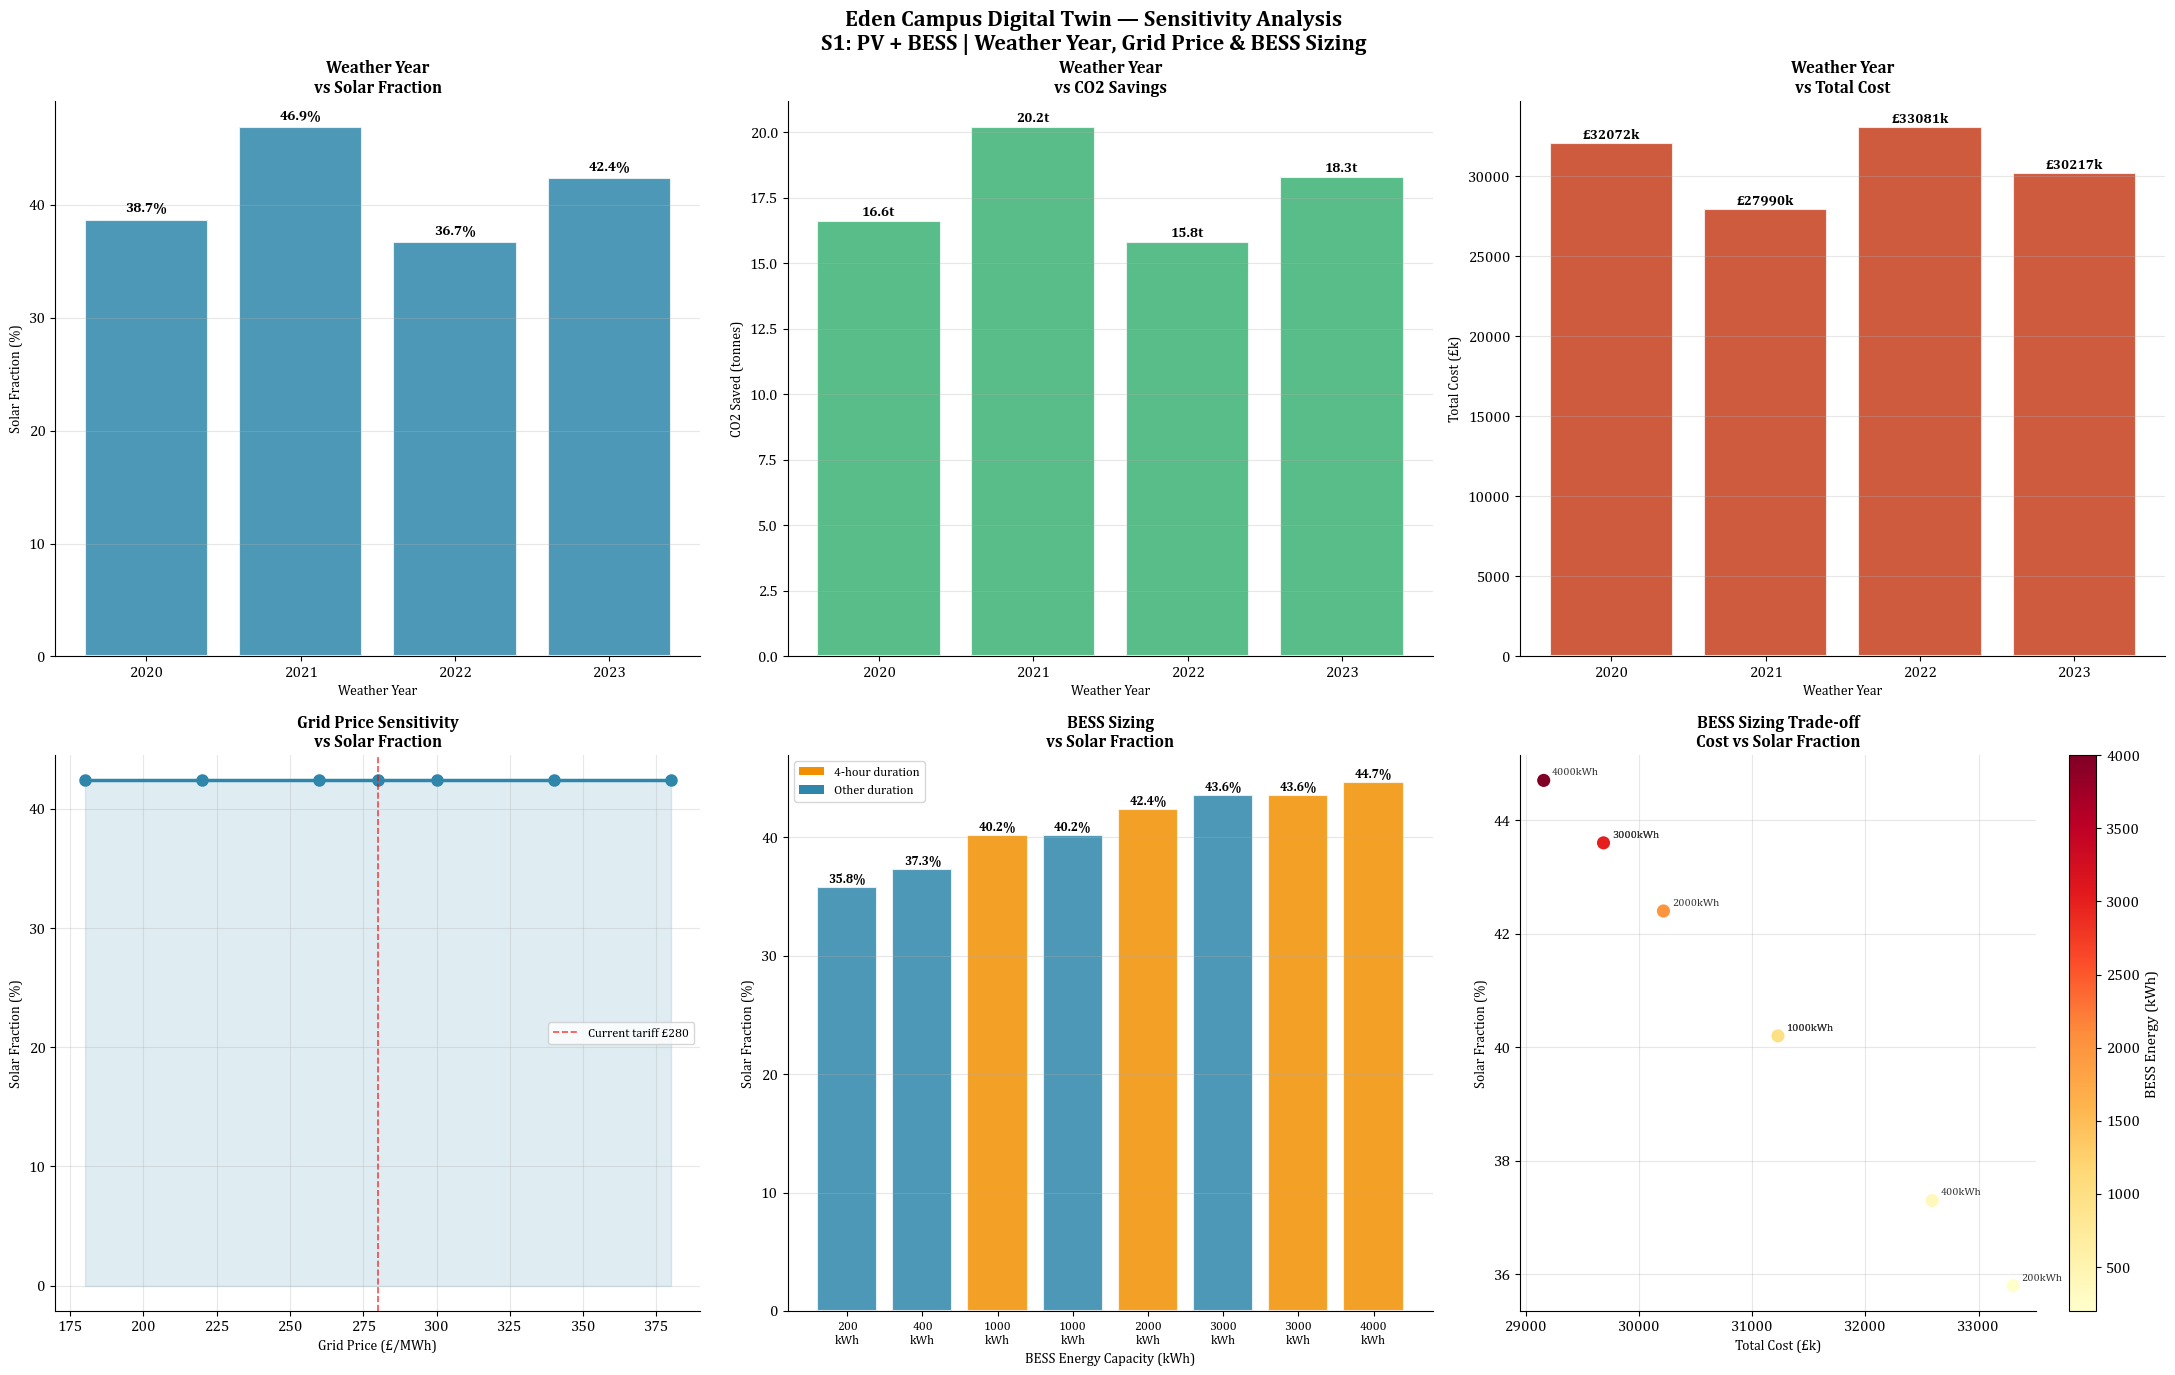

Sensitivity analysis chart saved!


In [4]:
fig, axes = plt.subplots(2, 3, figsize=(22, 14))
fig.suptitle(
    'Eden Campus Digital Twin — Sensitivity Analysis\n'
    'S1: PV + BESS | Weather Year, Grid Price & BESS Sizing',
    fontsize=16, fontweight='bold')

# ── WEATHER: Solar Fraction ──
ax = axes[0, 0]
years  = weather_df.index.tolist()
values = weather_df['Solar Fraction (%)'].values
bars   = ax.bar(years, values, color='#2E86AB',
                alpha=0.85, edgecolor='white', linewidth=1.5)
for bar, val in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.5,
            f'{val:.1f}%', ha='center', va='bottom',
            fontsize=10, fontweight='bold')
ax.set_title('Weather Year\nvs Solar Fraction', fontsize=12, fontweight='bold')
ax.set_ylabel('Solar Fraction (%)', fontsize=10)
ax.set_xlabel('Weather Year', fontsize=10)
ax.grid(True, alpha=0.3, axis='y')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# ── WEATHER: CO2 Saved ──
ax = axes[0, 1]
values = weather_df['CO2 Saved (tonnes)'].values
bars   = ax.bar(years, values, color='#3BB273',
                alpha=0.85, edgecolor='white', linewidth=1.5)
for bar, val in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.1,
            f'{val:.1f}t', ha='center', va='bottom',
            fontsize=10, fontweight='bold')
ax.set_title('Weather Year\nvs CO2 Savings', fontsize=12, fontweight='bold')
ax.set_ylabel('CO2 Saved (tonnes)', fontsize=10)
ax.set_xlabel('Weather Year', fontsize=10)
ax.grid(True, alpha=0.3, axis='y')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# ── WEATHER: Total Cost ──
ax = axes[0, 2]
values = weather_df['Total Cost (£k)'].values
bars   = ax.bar(years, values, color='#C73E1D',
                alpha=0.85, edgecolor='white', linewidth=1.5)
for bar, val in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 100,
            f'£{val:.0f}k', ha='center', va='bottom',
            fontsize=10, fontweight='bold')
ax.set_title('Weather Year\nvs Total Cost', fontsize=12, fontweight='bold')
ax.set_ylabel('Total Cost (£k)', fontsize=10)
ax.set_xlabel('Weather Year', fontsize=10)
ax.grid(True, alpha=0.3, axis='y')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# ── PRICE: Solar Fraction ──
ax = axes[1, 0]
prices = price_df.index.tolist()
values = price_df['Solar Fraction (%)'].values
ax.plot(prices, values, color='#2E86AB', linewidth=2.5,
        marker='o', markersize=8)
ax.fill_between(prices, values, alpha=0.15, color='#2E86AB')
ax.axvline(280, color='red', linewidth=1.2,
           linestyle='--', alpha=0.7, label='Current tariff £280')
ax.set_title('Grid Price Sensitivity\nvs Solar Fraction',
             fontsize=12, fontweight='bold')
ax.set_ylabel('Solar Fraction (%)', fontsize=10)
ax.set_xlabel('Grid Price (£/MWh)', fontsize=10)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# ── BESS: Solar Fraction by Energy ──
ax = axes[1, 1]
energies = sizing_df['BESS Energy (kWh)'].values
values   = sizing_df['Solar Fraction (%)'].values
colors_s = ['#F18F01' if h == 4 else '#2E86AB'
            for h in sizing_df['Duration (hrs)'].values]
bars     = ax.bar(range(len(energies)), values,
                  color=colors_s, alpha=0.85,
                  edgecolor='white', linewidth=1.5)
for bar, val in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.2,
            f'{val:.1f}%', ha='center', va='bottom',
            fontsize=9, fontweight='bold')
ax.set_xticks(range(len(energies)))
ax.set_xticklabels([f'{e:.0f}\nkWh' for e in energies], fontsize=9)
ax.set_title('BESS Sizing\nvs Solar Fraction',
             fontsize=12, fontweight='bold')
ax.set_ylabel('Solar Fraction (%)', fontsize=10)
ax.set_xlabel('BESS Energy Capacity (kWh)', fontsize=10)
from matplotlib.patches import Patch
ax.legend(handles=[
    Patch(facecolor='#F18F01', label='4-hour duration'),
    Patch(facecolor='#2E86AB', label='Other duration'),
], fontsize=9)
ax.grid(True, alpha=0.3, axis='y')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# ── BESS: Cost vs Solar Trade-off ──
ax = axes[1, 2]
costs  = sizing_df['Total Cost (£k)'].values
solar  = sizing_df['Solar Fraction (%)'].values
sizes  = sizing_df['BESS Energy (kWh)'].values
sc     = ax.scatter(costs, solar, c=sizes,
                    cmap='YlOrRd', s=120, zorder=3,
                    edgecolors='white', linewidth=1.5)
for i, (c, s, e) in enumerate(zip(costs, solar, sizes)):
    ax.annotate(f'{e:.0f}kWh',
                (c, s), textcoords='offset points',
                xytext=(6, 4), fontsize=8, color='#333333')
plt.colorbar(sc, ax=ax, label='BESS Energy (kWh)')
ax.set_title('BESS Sizing Trade-off\nCost vs Solar Fraction',
             fontsize=12, fontweight='bold')
ax.set_xlabel('Total Cost (£k)', fontsize=10)
ax.set_ylabel('Solar Fraction (%)', fontsize=10)
ax.grid(True, alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
save_path = os.path.join(base, "04_results/figures",
                          "sensitivity_analysis.png")
plt.savefig(save_path, dpi=150, bbox_inches='tight')
plt.show()
print("Sensitivity analysis chart saved!")

In [5]:
os.makedirs(os.path.join(base, "04_results/tables"), exist_ok=True)

# ── Save Excel ──
excel_path = os.path.join(base, "04_results/tables",
                           "sensitivity_analysis.xlsx")
with pd.ExcelWriter(excel_path, engine='openpyxl') as writer:
    weather_df.to_excel(writer, sheet_name='Weather Year')
    price_df.to_excel(writer,   sheet_name='Grid Price')
    sizing_df.to_excel(writer,  sheet_name='BESS Sizing',  index=False)
print(f"Excel saved: {excel_path}")

# ── Print LaTeX tables ──
print("\n── Weather Year LaTeX Table ──\n")
print(weather_df.to_latex(
    caption='Weather year sensitivity analysis for S1 (PV + BESS).',
    label='tab:sensitivity_weather',
    float_format='{:.1f}'.format))

print("\n── Grid Price LaTeX Table ──\n")
print(price_df[['Solar Fraction (%)',
                 'CO2 Saved (tonnes)',
                 'Total Cost (£k)']].to_latex(
    caption='Grid electricity price sensitivity analysis for S1 (PV + BESS).',
    label='tab:sensitivity_price',
    float_format='{:.1f}'.format))

print("\n── BESS Sizing LaTeX Table ──\n")
print(sizing_df.to_latex(
    index=False,
    caption='BESS capacity sizing sensitivity analysis for S1 (PV + BESS).',
    label='tab:sensitivity_bess',
    float_format='{:.1f}'.format))

print("\nAll sensitivity tables saved!")

Excel saved: /Users/everythingkrypto/Documents/EdenCampus_PhD/04_results/tables/sensitivity_analysis.xlsx

── Weather Year LaTeX Table ──

\begin{table}
\caption{Weather year sensitivity analysis for S1 (PV + BESS).}
\label{tab:sensitivity_weather}
\begin{tabular}{lrrrrrr}
\toprule
 & PV Generation (MWh) & Grid Import (MWh) & Solar Fraction (%) & CO2 Saved (tonnes) & Total Cost (£k) & Peak Import (kW) \\
Year &  &  &  &  &  &  \\
\midrule
2020 & 71.4 & 114.5 & 38.7 & 16.6 & 32071.9 & 656.7 \\
2021 & 86.6 & 100.0 & 46.9 & 20.2 & 27989.7 & 634.3 \\
2022 & 67.8 & 118.1 & 36.7 & 15.8 & 33081.4 & 667.3 \\
2023 & 78.3 & 107.9 & 42.4 & 18.3 & 30217.2 & 652.2 \\
\bottomrule
\end{tabular}
\end{table}


── Grid Price LaTeX Table ──

\begin{table}
\caption{Grid electricity price sensitivity analysis for S1 (PV + BESS).}
\label{tab:sensitivity_price}
\begin{tabular}{lrrr}
\toprule
 & Solar Fraction (%) & CO2 Saved (tonnes) & Total Cost (£k) \\
Grid Price (£/MWh) &  &  &  \\
\midrule
180 & 42.4 & 1